# Isothermal interface domain in the $(T_{0^-},\,n_B(0^-))$ window

Two boundaries bound the isothermal interface problem, and both are traced here
with a polar-ray solve rather than a 2D mesh scan.

The construction, the calibration and the mesh follow
`new_paper_calculations/26-08-18`; the physics is recorded in
`wiki/physics/isothermal-analytic-front-speed.md`.

In [1]:
from pathlib import Path

import numpy as np

import isothermal_domain_rays as idr

# Tunable run parameters
DOMAIN_CACHE = Path("26SU-13_isothermal_domain.npy")
THETA_COUNT = 12
PROBE_COUNT = 12
MAX_WORKERS = 8

print(f"parameter set        {idr.NM_TYPE}, paraQMCRMF3, ms = {idr.MS_MEV:g} MeV")
print(f"bag calibration      B14 = {idr.B14_MEV} MeV")
print(f"saturation density   n0  = {idr.N0_MEV3:.6g} MeV^3"
      f"  ({idr.N0_MEV3 / idr.MeV_fm**3:.3f} fm^-3)")
print(f"window               nB/n0 in [{idr.DENSITY_MIN_OVER_N0}, {idr.DENSITY_MAX_OVER_N0}], "
      f"T in [{idr.TEMPERATURE_MIN_MEV}, {idr.TEMPERATURE_MAX_MEV}] MeV")

parameter set        PNM, paraQMCRMF3, ms = 0 MeV
bag calibration      B14 = 189.1566 MeV
saturation density   n0  = 1.22936e+06 MeV^3  (0.160 fm^-3)
window               nB/n0 in [1.0, 5.5], T in [0.01, 120.0] MeV


## The two boundaries

Both come from a single upstream nuclear solve at each probe point, which
returns $\mu_B(0^-)$ and $P(0^-)$ on the branch-validated PNM mean-field branch.
They are the two velocity limits of the isothermal front.

**$\Delta\mu_B=0$: the $u(0^-)=0$ edge.**  Solve the quark state at the upstream
pressure and temperature with $\mu_K=0$ and compare baryon chemical potentials.
At common $P$ and $T$ the phase with the lower $\mu_B$ is favored:

$$
\Delta\mu_B \;=\; \mu_B^{\rm QM}\!\left[P(0^-),\,\mu_K = 0,\,T_{0^-}\right] \;-\; \mu_B(0^-).
$$

$\Delta\mu_B>0$ is stable neutron matter with no front; $\Delta\mu_B<0$ is
quark-matter-favored.  This is the gate `analytic_velocity_isothermal` applies.

**$a(0^+)=1$: the $u(0^-)\to\infty$ edge.**  The interface composition is the
local fraction $a(0^+)=n_K(0^+)/n_B(0^+)$, so its largest possible value is $1$:
the quark matter at the interface is at most as $K$-rich as the pure neutron
matter it came from.  Pin the composition there and solve the interface state
from the pressure match, leaving $\mu_B(0^+)$ free:

$$
P_{\rm QM}\!\left[\mu_B(0^+),\,\mu_K(0^+),\,T_{0^-}\right]=P(0^-),
\qquad
\frac{n_K(0^+)}{n_B(0^+)}=a(0^+)=1 .
$$

The boundary is where that state stops undercutting the upstream neutron matter
in Gibbs energy per baryon, $g=\mu_B+a\,\mu_K$:

$$
R_{a=1} \;=\; \mu_B(0^+)+a(0^+)\,\mu_K(0^+)-\mu_B(0^-) \;=\; 0 .
$$

**Why these are the velocity limits.**  At $a(0^+)\to0$ the Gibbs gap reduces
identically to $\Delta\mu_B$, and the closed-form speed vanishes with $a(0^+)$,
so the first boundary is $u(0^-)=0$.  The speed carries a $1/[1-a(0^+)]$ factor,
so the second is $u(0^-)\to\infty$.  The front exists strictly between them, on
the quark-favored side of $\Delta\mu_B=0$.

**Not `A_boundary`.**  That quantity belongs to the energy-conserving problem,
where $T(0^+)\neq T(0^-)$ and a conversion-layer trajectory selects the
composition.  The isothermal problem has only $a(0^+)$, whose maximum is $1$.

**Why rays.**  Both residuals are monotone in density, so both curves are star
shaped about the cold, low-density corner $(n_B/n_0=1,\,T=0)$.  In the
dimensionless elliptical coordinate of the 26-08-18 cluster grid,

$$
\rho = \sqrt{\left(\frac{n_B/n_0 - 1}{4.5}\right)^{2} + \left(\frac{T}{120\ {\rm MeV}}\right)^{2}},
\qquad
\theta = \arctan\!\left(\frac{T/120\ {\rm MeV}}{(n_B/n_0 - 1)/4.5}\right),
$$

every ray meets each curve exactly once, so each boundary point is a scalar root
solve in $\rho$ instead of a mesh refinement.

In [2]:
if DOMAIN_CACHE.exists():
    DOMAIN = idr.load_payload(DOMAIN_CACHE)
    print(f"loaded cached trace from {DOMAIN_CACHE}")
else:
    DOMAIN = idr.solve_domain(
        theta_count=THETA_COUNT,
        probe_count=PROBE_COUNT,
        max_workers=MAX_WORKERS,
    )
    idr.save_payload(DOMAIN, DOMAIN_CACHE)
    print(f"wrote {DOMAIN_CACHE}")

CURVES = {kind: idr.boundary_curve(DOMAIN, kind) for kind in idr.BOUNDARY_KINDS}

print(f"\nrays: {len(DOMAIN['rays'])}   "
      f"nuclear solves: {sum(ray['evaluation_count'] for ray in DOMAIN['rays'])}")
for kind, curve in CURVES.items():
    print(f"{kind:24s} {curve['nB_over_n0'].size:2d}/{len(DOMAIN['rays'])} roots")

print(f"\n{'theta':>7} | {'delta_muB = 0  (u = 0)':^22} | "
      f"{'a_0plus = 1  (u -> inf)':^34}")
print(f"{'(deg)':>7} | {'nB/n0':>9} {'T (MeV)':>11} | "
      f"{'nB/n0':>9} {'T (MeV)':>11} {'nB(0+)/nB(0-)':>13}")
print("-" * 74)
for ray in DOMAIN["rays"]:
    fields = []
    for kind in idr.BOUNDARY_KINDS:
        record = ray[kind]
        if record.get("status") == "root":
            fields.append(f"{record['nB_over_n0']:9.4f} {record['T_0minus_MeV']:11.4f}")
        else:
            fields.append(f"{record.get('status', 'missing'):>21}")
    ceiling = ray["a_0plus_equals_one"]
    jump = (f"{ceiling['compression_ratio']:13.3f}"
            if ceiling.get("status") == "root" else f"{'-':>13}")
    print(f"{ray['theta_deg']:7.2f} | {fields[0]} | {fields[1]}{jump}")

loaded cached trace from 26SU-13_isothermal_domain.npy

rays: 12   nuclear solves: 217
delta_muB_equals_zero    12/12 roots
a_0plus_equals_one       12/12 roots

  theta | delta_muB = 0  (u = 0) |      a_0plus = 1  (u -> inf)      
  (deg) |     nB/n0     T (MeV) |     nB/n0     T (MeV) nB(0+)/nB(0-)
--------------------------------------------------------------------------
   0.00 |    3.0000      0.0100 |    5.2979      0.0100        1.573
   1.82 |    2.9988      1.6963 |    5.2945      3.6446        1.572
   7.14 |    2.9821      6.6243 |    5.2451     14.1877        1.564
  15.53 |    2.9169     14.2059 |    5.0527     30.0342        1.535
  26.31 |    2.7710     23.3477 |    4.6245     47.7818        1.476
  38.60 |    2.5371     32.7168 |    3.9655     63.1183        1.405
  51.40 |    2.2372     41.3348 |    3.2095     73.8176        1.377
  63.69 |    1.9056     48.8480 |    2.5012     80.9735        1.443
  74.47 |    1.5755     55.2199 |    1.8994     86.3045        1.628
  

## Validation against the published coexistence densities

`wiki/physics/isothermal-analytic-front-speed.md` tabulates the neutron-side
equilibrated coexistence densities for this bag calibration.  Re-solving them on
fixed-$T$ paths is an independent check of the ray trace: a different path mode,
its own brackets, seeded only by the published density.  $T = 0$ is not an
admissible state of the microphysics, so the cold entry is checked at
$T = 10^{-2}$ MeV.

In [3]:
VALIDATION = idr.validate_against_wiki(max_workers=4)

print(f"{'T (MeV)':>8} {'wiki nB/n0':>12} {'re-solved':>12} {'difference':>12}")
print("-" * 48)
for row in VALIDATION:
    if row["status"] != "root":
        print(f"{row['temperature_MeV']:8.1f} {row['reference_nB_over_n0']:12.4f} "
              f"{'FAILED':>12}   {row.get('message', '')[:40]}")
        continue
    print(f"{row['temperature_MeV']:8.1f} {row['reference_nB_over_n0']:12.4f} "
          f"{row['solved_nB_over_n0']:12.4f} {row['absolute_error']:12.2e}")

WORST = np.nanmax([abs(row["absolute_error"]) for row in VALIDATION])
print(f"\nlargest absolute deviation: {WORST:.2e} n0")

 T (MeV)   wiki nB/n0    re-solved   difference
------------------------------------------------
     0.0       3.0000       3.0000     2.17e-07
    20.0       2.8335       2.8334    -1.18e-04
    40.0       2.2923       2.2892    -3.05e-03
    60.0       1.3247       1.3060    -1.87e-02

largest absolute deviation: 1.87e-02 n0


## The domain

The two boundaries and the region between them, on the same axes as the
energy-conserving contour figure so the curves can be compared directly.  The
front exists only inside the band: $u(0^-)$ rises from zero on the
$\Delta\mu_B=0$ edge to divergence on the $a(0^+)=1$ edge.

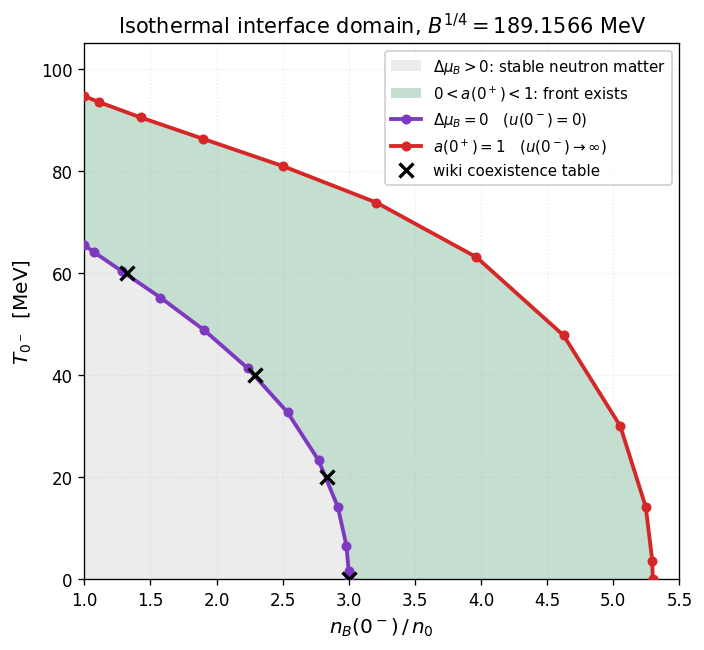

wrote 26SU-13_isothermal_domain.png

cold ends:  delta_muB=0 at 3.000 n0, a(0+)=1 at 5.298 n0
hot ends :  delta_muB=0 at 65.5 MeV, a(0+)=1 at 94.7 MeV


In [4]:
# Tunable plotting parameters
FIGURE_SIZE = (6.4, 5.8)
FIGURE_DPI = 120
TITLE_FONT_SIZE = 12.5
AXIS_LABEL_FONT_SIZE = 12
TICK_LABEL_FONT_SIZE = 10
LEGEND_FONT_SIZE = 9
ANNOTATION_FONT_SIZE = 9.5
LINE_WIDTH = 2.3
MARKER_SIZE = 5.0
REFERENCE_MARKER_SIZE = 8.5
REFERENCE_MARKER_STYLE = "x"
REFERENCE_MARKER_EDGE_WIDTH = 2.0
GRID_ALPHA = 0.25
GRID_LINE_STYLE = ":"
BAND_ALPHA = 0.28
REGION_ALPHA = 0.13
DELTA_MUB_COLOR = "#7d3ac1"
A_CEILING_COLOR = "#d62728"
BAND_COLOR = "#2e8b57"
STABLE_REGION_COLOR = "#6d6d6d"
REFERENCE_COLOR = "black"
DENSITY_LIMITS = (1.0, 5.5)
TEMPERATURE_LIMITS = (0.0, 105.0)
LEGEND_LOCATION = "upper right"
EXPORT_PATH = "26SU-13_isothermal_domain.png"
EXPORT_DPI = 200

import matplotlib.pyplot as plt

gate = CURVES["delta_muB_equals_zero"]
ceiling = CURVES["a_0plus_equals_one"]
gate_path = list(zip(gate["nB_over_n0"], gate["T_0minus_MeV"]))
ceiling_path = list(zip(ceiling["nB_over_n0"], ceiling["T_0minus_MeV"]))

figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI)

# Both curves are traced on the same theta axis and both terminate on the
# nB = n0 edge, so the band closes on the curves themselves with no window
# corners involved.
band = ceiling_path + list(reversed(gate_path))
stable = gate_path + [(DENSITY_LIMITS[0], 0.0)]
for polygon, color, alpha, label in (
    (stable, STABLE_REGION_COLOR, REGION_ALPHA,
     r"$\Delta\mu_B>0$: stable neutron matter"),
    (band, BAND_COLOR, BAND_ALPHA, r"$0<a(0^+)<1$: front exists"),
):
    xs, ys = zip(*polygon)
    axis.fill(xs, ys, color=color, alpha=alpha, linewidth=0, label=label, zorder=1)

axis.plot(gate["nB_over_n0"], gate["T_0minus_MeV"], "-o", color=DELTA_MUB_COLOR,
          linewidth=LINE_WIDTH, markersize=MARKER_SIZE, zorder=3,
          label=r"$\Delta\mu_B=0$   ($u(0^-)=0$)")
axis.plot(ceiling["nB_over_n0"], ceiling["T_0minus_MeV"], "-o", color=A_CEILING_COLOR,
          linewidth=LINE_WIDTH, markersize=MARKER_SIZE, zorder=3,
          label=r"$a(0^+)=1$   ($u(0^-)\to\infty$)")
axis.plot([reference for _, reference in idr.WIKI_COEXISTENCE_REFERENCE],
          [temperature for temperature, _ in idr.WIKI_COEXISTENCE_REFERENCE],
          REFERENCE_MARKER_STYLE, color=REFERENCE_COLOR, linestyle="none",
          markersize=REFERENCE_MARKER_SIZE,
          markeredgewidth=REFERENCE_MARKER_EDGE_WIDTH, zorder=4,
          label="wiki coexistence table")

axis.set_xlim(*DENSITY_LIMITS)
axis.set_ylim(*TEMPERATURE_LIMITS)
axis.set_xlabel(r"$n_B(0^-)\,/\,n_0$", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_ylabel(r"$T_{0^-}$  [MeV]", fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_title(f"Isothermal interface domain, $B^{{1/4}}={idr.B14_MEV}$ MeV",
               fontsize=TITLE_FONT_SIZE)
axis.tick_params(labelsize=TICK_LABEL_FONT_SIZE)
axis.grid(alpha=GRID_ALPHA, linestyle=GRID_LINE_STYLE)
axis.legend(loc=LEGEND_LOCATION, fontsize=LEGEND_FONT_SIZE, framealpha=0.92)

figure.savefig(EXPORT_PATH, dpi=EXPORT_DPI, bbox_inches="tight")
plt.show()
print(f"wrote {EXPORT_PATH}")

print(f"\ncold ends:  delta_muB=0 at {gate['nB_over_n0'].max():.3f} n0, "
      f"a(0+)=1 at {ceiling['nB_over_n0'].max():.3f} n0")
print(f"hot ends :  delta_muB=0 at {gate['T_0minus_MeV'].max():.1f} MeV, "
      f"a(0+)=1 at {ceiling['T_0minus_MeV'].max():.1f} MeV")